# NAME: BAVYA SRI B
# REG NO: 212224230034

In [ ]:
!pip install git+https://github.com/andreinechaev/nvcc4jupyter.git
%load_ext nvcc4jupyter

  Cloning https://github.com/andreinechaev/nvcc4jupyter.git to /tmp/pip-req-build-qicldq3d
  Running command git clone --filter=blob:none --quiet https://github.com/andreinechaev/nvcc4jupyter.git /tmp/pip-req-build-qicldq3d
  Resolved https://github.com/andreinechaev/nvcc4jupyter.git to commit 173e636d9a3cb81c6101a160c1c8c86864eaaf5b
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for nvcc4jupyter: filename=nvcc4jupyter-1.2.2-py3-none-any.whl size=12545 sha256=f293982cdc354d66d92473c4350316b6ff6623d7028219d8cf93377ffb402266
  Stored in directory: /tmp/pip-ephem-wheel-cache-_yrgbmre/wheels/2f/1e/79/584a8d85ad018ecc510baa90d4fbc161bd56a4d66943d5b0d4
Successfully built nvcc4jupyter
Detected platform "Colab". Running its setup...
Source files will be saved in "/tmp/tmpgvdsy45o".


In [ ]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0


In [ ]:
%load_ext nvcc4jupyter

The nvcc4jupyter extension is already loaded. To reload it, use:
  %reload_ext nvcc4jupyter


In [ ]:
from pathlib import Path

file_path = Path('/absolute/path/to/images.jpeg')
if file_path.exists():
    print("File exists!")
else:
    print("File does not exist!")

File does not exist!


In [ ]:
import os
print("Current Working Directory:", os.getcwd())

Current Working Directory: /content


In [ ]:

from google.colab import files
uploaded = files.upload()

Saving butterfly.jpg to butterfly.jpg


In [ ]:
from pathlib import Path

# Assuming the file is in the same directory as the notebook
file_path = Path('butterfly.jpg')
if file_path.exists():
    print("File exists!")
else:
    print("File does not exist!")

File exists!


In [ ]:
pwd

'/content'

In [ ]:
ls /content/butterfly.jpg

/content/butterfly.jpg


In [ ]:
import cv2
image = cv2.imread('/content/butterfly.jpg')
if image is None:
    print("Error: Image not found or unable to read the image.")
else:
    print("Image read successfully.")


Image read successfully.


In [25]:
%%writefile sobelEdgeDetectionFilter.cu
#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <cuda_runtime.h>
#include <opencv2/opencv.hpp>

using namespace cv;

__global__ void sobelFilter(unsigned char *srcImage, unsigned char *dstImage, unsigned int width, unsigned int height) {
    //Write your code here
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    float Kx[3][3] = { -1, 0, 1, -2, 0, 2, -1, 0, 1 };
    float Ky[3][3] = { 1, 2, 1, 0, 0, 0, -1, -2, -1 };

    // only threads inside image will write results
    if ((x >= 3 / 2) && (x < (width - 3 / 2)) && (y >= 3 / 2) && (y < (height - 3 / 2))) {
        // Gradient in x-direction
        float Gx = 0;
        for (int ky = -3 / 2; ky <= 3 / 2; ky++) {
            for (int kx = -3 / 2; kx <= 3 / 2; kx++) {
                float fl = srcImage[((y + ky) * width + (x + kx))];
                Gx += fl * Kx[ky + 3 / 2][kx + 3 / 2];
            }
        }
        float Gx_abs = Gx < 0 ? -Gx : Gx;

        // Gradient in y-direction
        float Gy = 0;
        for (int ky = -3 / 2; ky <= 3 / 2; ky++) {
            for (int kx = -3 / 2; kx <= 3 / 2; kx++) {
                float fl = srcImage[((y + ky) * width + (x + kx))];
                Gy += fl * Ky[ky + 3 / 2][kx + 3 / 2];
            }
        }
        float Gy_abs = Gy < 0 ? -Gy : Gy;

        // Cap the value at 255 to prevent overflow
        float val = Gx_abs + Gy_abs;
        if (val > 255) val = 255;

        dstImage[(y * width + x)] = val;
    }
}

void checkCudaErrors(cudaError_t r) {
    if (r != cudaSuccess) {
        fprintf(stderr, "CUDA Error: %s\n", cudaGetErrorString(r));
        exit(EXIT_FAILURE);
    }
}

int main() {
    // Read input image as GRAYSCALE (Sobel requires 1 channel)
    Mat image = imread("/content/butterfly.jpg", IMREAD_GRAYSCALE);

    if (image.empty()) {
        printf("Error: Image not found. Check your path in the Colab folder.\n");
        return -1;
    }

    int width = image.cols;
    int height = image.rows;
    size_t imageSize = width * height * sizeof(unsigned char);

    unsigned char *h_outputImage = (unsigned char *)malloc(imageSize);
    if (h_outputImage == nullptr) {
        fprintf(stderr, "Failed to allocate host memory\n");
        return -1;
    }

    unsigned char *d_inputImage, *d_outputImage;
    checkCudaErrors(cudaMalloc(&d_inputImage, imageSize));
    checkCudaErrors(cudaMalloc(&d_outputImage, imageSize));
    checkCudaErrors(cudaMemcpy(d_inputImage, image.data, imageSize, cudaMemcpyHostToDevice));

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    dim3 blockSize(16, 16);
    dim3 gridSize(ceil(width / 16.0), ceil(height / 16.0));

    cudaEventRecord(start);

    // FIXED LINE: Added gridSize, blockSize, and corrected angle brackets
    sobelFilter<<<gridSize, blockSize>>>(d_inputImage, d_outputImage, width, height);

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float milliseconds = 0;
    cudaEventElapsedTime(&milliseconds, start, stop);

    checkCudaErrors(cudaMemcpy(h_outputImage, d_outputImage, imageSize, cudaMemcpyDeviceToHost));

    Mat outputImage(height, width, CV_8UC1, h_outputImage);
    imwrite("output_sobel.jpeg", outputImage);

    free(h_outputImage);
    cudaFree(d_inputImage);
    cudaFree(d_outputImage);
    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    printf("Total time taken: %f milliseconds\n", milliseconds);

    return 0;
}

Overwriting sobelEdgeDetectionFilter.cu


In [26]:
!apt-get update -qq
!apt-get install -y libopencv-dev pkg-config

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
pkg-config is already the newest version (1.8.1-2build1).
0 upgraded, 0 newly installed, 0 to remove and 95 not upgraded.


In [27]:
!pkg-config --modversion opencv4

4.6.0


In [28]:
!nvcc -o sobelEdgeDetectionFilter sobelEdgeDetectionFilter.cu `pkg-config --cflags --libs opencv4`


/usr/include/opencv4/opencv2/stitching/detail/warpers.hpp(235): warning #611-D: overloaded virtual function "cv::detail::PlaneWarper::buildMaps" is only partially overridden in class "cv::detail::AffineWarper"
  class AffineWarper : public PlaneWarper
        ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

/usr/include/opencv4/opencv2/stitching/detail/warpers.hpp(235): warning #611-D: overloaded virtual function "cv::detail::PlaneWarper::warp" is only partially overridden in class "cv::detail::AffineWarper"
  class AffineWarper : public PlaneWarper
        ^

/usr/include/opencv4/opencv2/stitching/detail/blenders.hpp(100): warning #611-D: overloaded virtual function "cv::detail::Blender::prepare" is only partially overridden in class "cv::detail::FeatherBlender"
  class FeatherBlender : public Blender
        ^

/usr/include/opencv4/opencv2/stitching/detail/blenders.hpp(127): warning #611-D: overloaded virtual function "cv::detail::Blender::prepare" is

In [29]:
!./sobelEdgeDetectionFilter

Total time taken: 0.170752 milliseconds


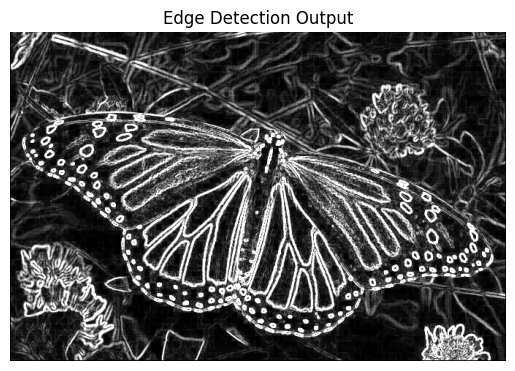

In [30]:
import cv2
from matplotlib import pyplot as plt
import os

# Read and display the output image
output_image_path = '/content/output_sobel.jpeg'

if not os.path.exists(output_image_path):
    print(f"Error: The output file '{output_image_path}' was not found. Please fix the compiler errors in your CUDA cell first.")
else:
    output_image = cv2.imread(output_image_path, cv2.IMREAD_GRAYSCALE)
    if output_image is None:
        print("Error: Failed to read the image.")
    else:
        # Display the image
        plt.imshow(output_image, cmap='gray')
        plt.title('Edge Detection Output')
        plt.axis('off')  # Hide the axes
        plt.show()